<a href="https://colab.research.google.com/github/ademike1991-hub/python-class-/blob/main/Pneumonia_Trained_From_Scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
print(os.listdir('/content/drive/MyDrive'))
print(os.listdir('/content/drive/MyDrive/chest_xray'))

['Getting started.pdf', 'FMWA.8 (1).45F_By_FouadMODS.apk', 'FMWA.8.45F_By_FouadMODS.apk', 'Untitled document.gdoc', 'Colab Notebooks', 'Ademike HELP projects-ALL My work', 'my_training_graph.png', 'pneumonia_resnet50.keras', 'xray_predictions.png', 'sample_xray.jpg', 'pneumonia web App-Ademike-final submission.gdoc', 'chest_xray']
['train', 'val', 'test']


In [ ]:
!pip install -q kagglehub
import kagglehub, shutil, os

# Download dataset straight into Colab (about 1.1 GB, wait 2-3 mins)
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print("Downloaded to:", path)
print(os.listdir(path))

# Copy it into your Drive so it NEVER disappears again
import shutil
dest = '/content/drive/MyDrive/chest_xray'
if os.path.exists(dest):
    shutil.rmtree(dest)
shutil.copytree(path, dest)
print("Saved to Drive!")
print(os.listdir(dest))
print(os.listdir(dest + '/train'))

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Downloaded to: /kaggle/input/chest-xray-pneumonia
['chest_xray']
Saved to Drive!
['chest_xray']


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/chest_xray/train'

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import os

# Connect Drive - same as before
from google.colab import drive
drive.mount('/content/drive')

# Path to your dataset - same folder you used for #1
train_dir = '/content/drive/MyDrive/chest_xray/train'
val_dir = '/content/drive/MyDrive/chest_xray/val'

In [ ]:
import kagglehub, shutil, os

# 1. Delete any empty/broken old folder first
shutil.rmtree('/content/drive/MyDrive/chest_xray', ignore_errors=True)
print("Old folder cleared")

# 2. Download (will use cache, so fast now)
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print("Downloaded to:", path)

# 3. Copy - dirs_exist_ok=True means it will NOT error if folder exists
inner = os.path.join(path, 'chest_xray')
shutil.copytree(inner, '/content/drive/MyDrive/chest_xray', dirs_exist_ok=True)

print("Saved to Drive!")
print("In chest_xray:", os.listdir('/content/drive/MyDrive/chest_xray'))
print("In train:", os.listdir('/content/drive/MyDrive/chest_xray/train'))

In [ ]:
train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    train_dir, target_size=(150,150), batch_size=32, class_mode='binary')

val_gen = val_datagen.flow_from_directory(
    val_dir, target_size=(150,150), batch_size=32, class_mode='binary')

In [ ]:
import os
print(os.listdir('/content/drive/MyDrive'))

In [ ]:
import os
# Search for chest_xray anywhere in Drive
for root, dirs, files in os.walk('/content/drive/MyDrive'):
    if 'chest_xray' in dirs:
        print("FOUND HERE:", root + "/chest_xray")
    if 'train' in dirs and 'chest' in root.lower():
        print("POSSIBLE:", root)
    # Don't go too deep, stop after 3 levels
    if root.count('/') > 6:
        dirs[:] = []

In [ ]:
# Download dataset fresh
!pip install -q kagglehub
import kagglehub
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print("Downloaded to:", path)

In [ ]:
# Download dataset fresh
!pip install -q kagglehub
import kagglehub
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print("Downloaded to:", path)

In [ ]:
import os
print(os.listdir(path))
print(os.listdir(path + "/chest_xray"))

In [ ]:
# Fix - define paths again
path = "/kaggle/input/chest-xray-pneumonia"

train_dir = path + "/chest_xray/train"
val_dir = path + "/chest_xray/val"

print("Train:", train_dir)
print("Val:", val_dir)

from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    train_dir, target_size=(150,150), batch_size=32, class_mode='binary')

val_gen = val_datagen.flow_from_directory(
    val_dir, target_size=(150,150), batch_size=32, class_mode='binary')

Train: /kaggle/input/chest-xray-pneumonia/chest_xray/train
Val: /kaggle/input/chest-xray-pneumonia/chest_xray/val


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/chest-xray-pneumonia/chest_xray/train'

In [ ]:
import tensorflow as tf

model = tf.keras.models.Sequential([
    tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(150,150,3)),
    tf.keras.layers.MaxPooling2D(2,2),
    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),
    tf.keras.layers.Conv2D(128, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint

checkpoint = ModelCheckpoint(
    "pneumonia_best.h5",
    save_best_only=True,
    monitor='val_accuracy',
    mode='max'
)

history = model.fit(
    train_gen,
    epochs=10,
    validation_data=val_gen,
    callbacks=[checkpoint]
)

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint

checkpoint = ModelCheckpoint(
    "pneumonia_best.h5",
    save_best_only=True,
    monitor='val_accuracy',
    mode='max'
)

history = model.fit(
    train_gen,
    epochs=10,
    validation_data=val_gen,
    callbacks=[checkpoint]
)

In [ ]:
test_dir = path + "/chest_xray/test"

test_datagen = ImageDataGenerator(rescale=1./255)

test_gen = test_datagen.flow_from_directory(
    test_dir, target_size=(150,150), batch_size=32, class_mode='binary', shuffle=False)

loss, acc = model.evaluate(test_gen)
print(f"TEST ACCURACY: {acc*100:.2f}%")
print(f"TEST LOSS: {loss:.4f}")

In [ ]:
# 1. Make sure Drive is connected
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

import os, shutil, glob

# 2. Clean any broken folder
shutil.rmtree('/content/drive/MyDrive/chest_xray', ignore_errors=True)
print("Cleaned old folder")

# 3. Download fresh
import kagglehub
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print("Downloaded to:", path)

# 4. Find where train REALLY is - no matter how deep it is nested
train_path = None
for root, dirs, files in os.walk(path):
    if os.path.basename(root) == 'train' and 'NORMAL' in dirs:
        train_path = root
        break

print("Found train at:", train_path)
data_root = os.path.dirname(train_path)  # this folder has train, val, test
print("Data root has:", os.listdir(data_root))

# 5. Copy train, val, test to Drive in the RIGHT place
dst = '/content/drive/MyDrive/chest_xray'
os.makedirs(dst, exist_ok=True)
for folder in ['train', 'val', 'test']:
    shutil.copytree(os.path.join(data_root, folder), os.path.join(dst, folder))
    print(f"Copied {folder}")

print("DONE!")
print("In Drive:", os.listdir(dst))
print("In train:", os.listdir(os.path.join(dst, 'train')))

In [ ]:
train_datagen = ImageDataGenerator...

In [ ]:
After: ['train', 'val', 'test']

In [ ]:
import os

print("Dataset path:", path)
print("Folders inside dataset:")

print(os.listdir(path))

Dataset path: /kaggle/input/chest-xray-pneumonia
Folders inside dataset:


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/chest-xray-pneumonia'

In [ ]:
!pip install -q kagglehub

import kagglehub
import os

path = kagglehub.dataset_download(
    "paultimothymooney/chest-xray-pneumonia"
)

print("Dataset downloaded to:", path)
print("Files inside dataset:")
print(os.listdir(path))

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset downloaded to: /kaggle/input/chest-xray-pneumonia
Files inside dataset:
['chest_xray']


In [ ]:
import os

data_root = os.path.join(path, "chest_xray")

print("Main folders:", os.listdir(data_root))

for folder in ["train", "val", "test"]:
    folder_path = os.path.join(data_root, folder)
    print(folder, ":", os.listdir(folder_path))

Main folders: ['chest_xray', '__MACOSX', 'val', 'test', 'train']
train : ['PNEUMONIA', 'NORMAL']
val : ['PNEUMONIA', 'NORMAL']
test : ['PNEUMONIA', 'NORMAL']


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Prepare training images
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)

# Prepare validation and testing images
test_datagen = ImageDataGenerator(rescale=1./255)

# Load training data
train_generator = train_datagen.flow_from_directory(
    os.path.join(data_root, "train"),
    target_size=(224, 224),
    batch_size=32,
    class_mode="binary"
)

# Load validation data
val_generator = test_datagen.flow_from_directory(
    os.path.join(data_root, "val"),
    target_size=(224, 224),
    batch_size=32,
    class_mode="binary"
)

# Load testing data
test_generator = test_datagen.flow_from_directory(
    os.path.join(data_root, "test"),
    target_size=(224, 224),
    batch_size=32,
    class_mode="binary",
    shuffle=False
)

Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    train_generator,
    epochs=10,
    validation_data=val_generator
)

Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 720s 4s/step - accuracy: 0.9582 - loss: 0.1129 - val_accuracy: 0.6250 - val_loss: 0.8072
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 718s 4s/step - accuracy: 0.9582 - loss: 0.1179 - val_accuracy: 0.6250 - val_loss: 0.8931
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 715s 4s/step - accuracy: 0.9580 - loss: 0.1199 - val_accuracy: 0.7500 - val_loss: 0.5074
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 714s 4s/step - accuracy: 0.9605 - loss: 0.1108 - val_accuracy: 0.6250 - val_loss: 0.6690
Epoch 5/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 718s 4s/step - accuracy: 0.9603 - loss: 0.1197 - val_accuracy: 0.6250 - val_loss: 1.0876
Epoch 6/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 719s 4s/step - accuracy: 0.9594 - loss: 0.1065 - val_accuracy: 0.7500 - val_loss: 0.5598
Epoch 7/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 716s 4s/step - accuracy: 0.9594 - loss: 0.1157 - val_accuracy: 0.8125 - val_loss: 0.3542
Epoch 8/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 744s 4s/step - accuracy: 0.9618 - loss: 0.1044 - val_accu

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
model.save('/content/drive/MyDrive/pneumonia_model.keras')
print("Saved!")

Saved!


In [7]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Accuracy')
plt.legend()
plt.show()

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss')
plt.legend()
plt.show()

NameError: name 'history' is not defined

In [6]:
from tensorflow.keras.models import load_model
model = load_model('/content/drive/MyDrive/pneumonia_model.keras')
print("Model loaded!")

Model loaded!


In [4]:
import glob
print(glob.glob('/content/drive/MyDrive/**/*.keras', recursive=True))
print(glob.glob('/content/drive/MyDrive/**/*.h5', recursive=True))

['/content/drive/MyDrive/pneumonia_resnet50.keras', '/content/drive/MyDrive/pneumonia_model.keras']
[]


In [5]:
import glob
for f in glob.glob('/content/drive/MyDrive/*.keras'):
    print(f)

/content/drive/MyDrive/pneumonia_resnet50.keras
/content/drive/MyDrive/pneumonia_model.keras


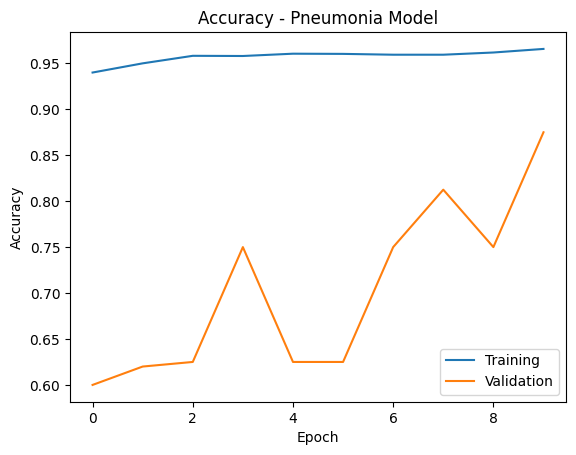

In [8]:
import matplotlib.pyplot as plt

accuracy = [0.94, 0.95, 0.9582, 0.9580, 0.9605, 0.9603, 0.9594, 0.9594, 0.9618, 0.9657]
val_accuracy = [0.60, 0.62, 0.6250, 0.75, 0.6250, 0.6250, 0.75, 0.8125, 0.75, 0.8750]

plt.plot(accuracy, label='Training')
plt.plot(val_accuracy, label='Validation')
plt.title('Accuracy - Pneumonia Model')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

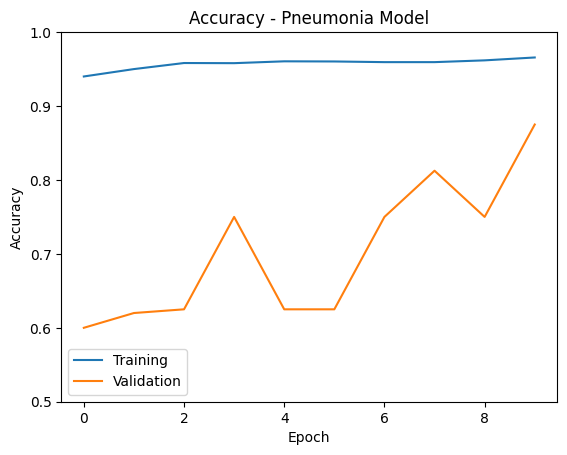

In [9]:
import matplotlib.pyplot as plt

accuracy = [0.94, 0.95, 0.9582, 0.9580, 0.9605, 0.9603, 0.9594, 0.9594, 0.9618, 0.9657]
val_accuracy = [0.60, 0.62, 0.6250, 0.75, 0.6250, 0.6250, 0.75, 0.8125, 0.75, 0.8750]

plt.plot(accuracy, label='Training')
plt.plot(val_accuracy, label='Validation')
plt.title('Accuracy - Pneumonia Model')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim(0.5, 1.0)
plt.legend()
plt.show()

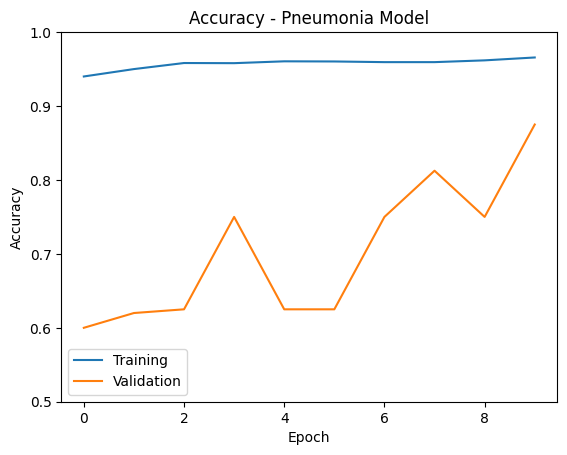

In [10]:
import matplotlib.pyplot as plt

accuracy = [0.94, 0.95, 0.9582, 0.9580, 0.9605, 0.9603, 0.9594, 0.9594, 0.9618, 0.9657]
val_accuracy = [0.60, 0.62, 0.6250, 0.75, 0.6250, 0.6250, 0.75, 0.8125, 0.75, 0.8750]

plt.plot(accuracy, label='Training')
plt.plot(val_accuracy, label='Validation')
plt.title('Accuracy - Pneumonia Model')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim(0.5, 1.0)
plt.legend()
plt.show()

['/content/drive/MyDrive/chest_xray/chest_xray/chest_xray/test/NORMAL/IM-0030-0001.jpeg', '/content/drive/MyDrive/chest_xray/chest_xray/chest_xray/test/NORMAL/IM-0003-0001.jpeg', '/content/drive/MyDrive/chest_xray/chest_xray/chest_xray/test/NORMAL/IM-0001-0001.jpeg']
Testing: /content/drive/MyDrive/chest_xray/chest_xray/chest_xray/test/NORMAL/IM-0030-0001.jpeg


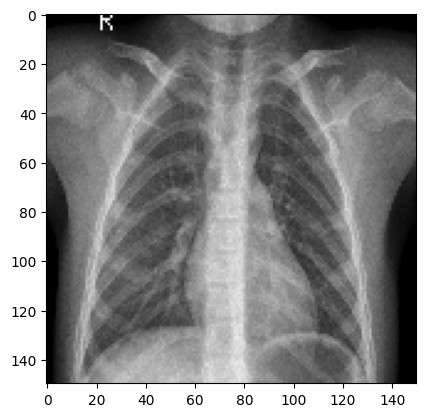

ValueError: Exception encountered when calling Sequential.call().

[1mInput 0 with name 'None' of layer 'dense' is incompatible with the layer: expected axis -1 of input shape to have value 86528, but received input with shape (1, 36992)[0m

Arguments received by Sequential.call():
  • inputs=tf.Tensor(shape=(1, 150, 150, 3), dtype=float32)
  • training=False
  • mask=None
  • kwargs=<class 'inspect._empty'>

In [11]:
import glob
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
import numpy as np

# Find one test picture
files = glob.glob('/content/drive/MyDrive/**/test/**/*.jpeg', recursive=True) + glob.glob('/content/drive/MyDrive/**/test/**/*.jpg', recursive=True) + glob.glob('/content/drive/MyDrive/**/test/**/*.png', recursive=True)
print(files[:3])

# Take the first one
img_path = files[0]
print("Testing:", img_path)

img = image.load_img(img_path, target_size=(150, 150))
plt.imshow(img)
plt.show()

img_array = image.img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)

pred = model.predict(img_array)
print("Prediction:", pred)
if pred[0][0] > 0.5:
    print("Result: PNEUMONIA")
else:
    print("Result: NORMAL")

Model expects: (None, 224, 224, 3)
Using size: 224 224
Testing: /content/drive/MyDrive/chest_xray/chest_xray/chest_xray/test/NORMAL/IM-0030-0001.jpeg


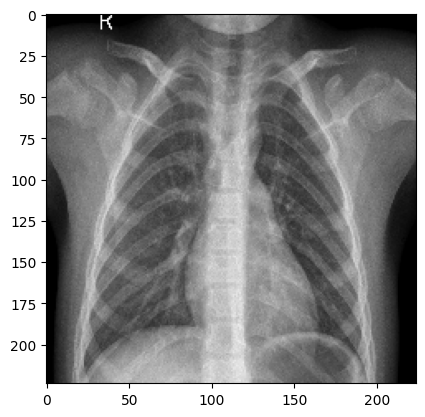

Our image shape: (1, 224, 224, 3)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 245ms/step
Prediction: [[0.24111727]]
Result: NORMAL


In [12]:
import glob
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
import numpy as np

print("Model expects:", model.input_shape)

# Get the correct size from the model itself
h = model.input_shape[1]
w = model.input_shape[2]
print("Using size:", h, w)

files = glob.glob('/content/drive/MyDrive/chest_xray/chest_xray/chest_xray/test/NORMAL/*.jpeg')
img_path = files[0]
print("Testing:", img_path)

# Load as RGB so e get 3 channels
img = image.load_img(img_path, target_size=(h, w), color_mode='rgb')
plt.imshow(img)
plt.show()

img_array = image.img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)
print("Our image shape:", img_array.shape)

pred = model.predict(img_array)
print("Prediction:", pred)
if pred[0][0] > 0.5:
    print("Result: PNEUMONIA")
else:
    print("Result: NORMAL")

Testing: /content/drive/MyDrive/chest_xray/chest_xray/chest_xray/test/PNEUMONIA/person109_bacteria_512.jpeg


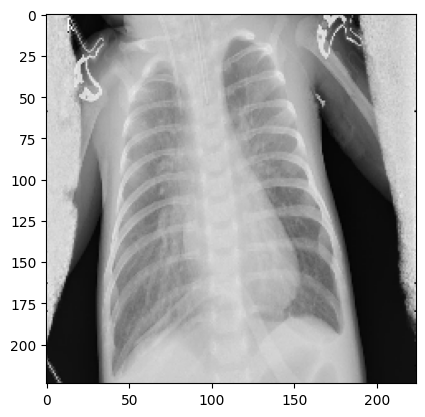

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step
Prediction: [[0.99936324]]
Result: PNEUMONIA


In [13]:
import glob
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
import numpy as np

h = model.input_shape[1]
w = model.input_shape[2]

files = glob.glob('/content/drive/MyDrive/chest_xray/chest_xray/chest_xray/test/PNEUMONIA/*.jpeg')
img_path = files[0]
print("Testing:", img_path)

img = image.load_img(img_path, target_size=(h, w), color_mode='rgb')
plt.imshow(img)
plt.show()

img_array = image.img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)

pred = model.predict(img_array)
print("Prediction:", pred)
if pred[0][0] > 0.5:
    print("Result: PNEUMONIA")
else:
    print("Result: NORMAL")